# AudioCFG — prototyp: globalny null CFG uczony odszumianiem dla zamrożonego Stable Audio Open

WIMU 2026Z, zespół 06: Jan Konarski, Jakub Szewczyk, Vladyslav Serhieiev. Gałąź `feat/learned-null`.

Notatnik zbiera cały prototyp w jednym miejscu: **hipotezę**, **sposób uruchomienia i odtworzenia** każdego kroku oraz **wyniki** (tabele i wykresy). Wszystkie liczby są czytane z plików w `results/` (zacommitowanych razem z manifestami), więc notatnik wykonuje się na CPU w kilkanaście sekund i nie wymaga GPU ani pobierania audio.

**Spis treści**
1. Hipoteza i kryterium
2. Jak uruchomić i odtworzyć
3. Krok 1 — trening nulla (P0)
4. Krok 2 — przemiatanie CFG
5. Krok 3 — ocena: zgodność, jakość, różnorodność
6. Wnioski, ograniczenia, dalsze kroki

## 1. Hipoteza i kryterium

**Hipoteza (za prowadzącym).** Wyuczenie *jednego globalnego* embeddingu „null” dla zamrożonego Stable Audio Open (SAO) poprawia jakość generacji przy porównywalnej zgodności z opisem i różnorodności — ponad to, co daje samo dostrojenie skali CFG. Ten sam embedding działa dla nowych promptów bez ponownego treningu.

**Co dokładnie jest uczone.** W SAO gałąź bezwarunkowa CFG dostaje w cross-attention sekwencję 130×768: 128 tokenów tekstu T5 i 2 tokeny czasu. Domyślnie cała jest zerowa (tak SAO był trenowany: dropout warunku zastępuje cross-attention zerami). Uczymy tylko tensor

$$N \in \mathbb{R}^{128\times 768},\qquad \text{uncond} = [\,N;\,0;\,0\,],$$

a warunek globalny (czas trwania) zostaje prawdziwy. Wagi DiT, VAE i T5 są zamrożone.

**Cel treningu** to zwykła strata odszumiania SAO (v-objective):
$x_t = \cos(\tfrac{\pi t}{2})\,x_0 + \sin(\tfrac{\pi t}{2})\,\varepsilon$,
$v = \cos(\tfrac{\pi t}{2})\,\varepsilon - \sin(\tfrac{\pi t}{2})\,x_0$,
$\mathcal{L}(N) = \mathbb{E}\,\lVert v_\theta(x_t, t, [N;0;0]) - v\rVert^2$,
liczona na audio muzycznym (FMA ∩ zbiór treningowy SAO), bez opisów.

**CFG:** $\hat v = v_\varnothing + g\,(v_c - v_\varnothing)$, konwencja diffusers ($g = 1$ to brak guidance).

**Trzy kroki (plik prowadzącego):**
1. Uczymy tylko null błędem odszumiania przy zamrożonym generatorze; porównujemy z oryginalnym SAO.
2. Dla obu wariantów robimy przemiatanie CFG na tych samych nowych promptach i seedach; dane oceny są rozłączne z danymi treningu nulla.
3. Oceniamy zgodność z opisem, jakość i różnorodność, sprawdzamy odsłuchem.

**Kryterium obalenia.** Jeżeli efekt wyuczonego nulla da się odtworzyć zmianą $g$ w oryginale, przewagi nie ma. Operacyjnie: dla każdego $g'$ wyuczonego nulla szukamy $g^*$, przy którym null zerowy ma **tę samą średnią zgodność CLAP**, i porównujemy jakość (Audiobox PQ) i różnorodność (CCDS) w tych dwóch punktach, z bootstrapowym 95% CI po promptach. Przewaga = ΔPQ > 0 z CI wykluczającym 0 i ΔCCDS nie spada istotnie.

## 2. Jak uruchomić i odtworzyć

**Instalacja** (Python ≥ 3.11):

```bash
git clone https://github.com/Nexonus/AudioCFG_WIMU_06_2026 && cd AudioCFG_WIMU_06_2026
git checkout feat/learned-null
python -m venv .venv && .venv/Scripts/activate      # Linux/macOS: source .venv/bin/activate
pip install -e ".[models,metrics,dev]"
pytest                                               # testy CPU (test GPU: pytest -m gpu)
```

Wagi SAO wymagają akceptacji licencji `stabilityai/stable-audio-open-1.0` na Hugging Face i `hf auth login`. Na Kaggle używamy lustrzanej kopii wag, której sha256 jest sprawdzany względem oficjalnych plików (`configs/sao_sha256.json`).

**Jedno polecenie na krok, jeden plik konfiguracyjny na krok:**

| Krok | Polecenie | Config | Wynik w repo |
|---|---|---|---|
| dane | `audiocfg prepare-data` | `configs/data.yaml` | `data/*.csv`, `data/data_manifest.json` |
| 1 | `audiocfg train-null <fma_large> <song_describer/audio>` | `configs/null_music_v1.yaml` | `results/null_music_v1/` |
| 2 | `audiocfg sweep --shard i --shards 2` → `audiocfg collect-sweep` | `configs/sweep_pilot_A.yaml` | `results/sweep_pilot_A/clips.parquet` |
| 3 | `audiocfg score <sweep_dir> --reference <song_describer/audio>` | `configs/score_pilot_A.yaml` | `results/score_pilot_A/` |
| analiza | `audiocfg analyze` | — | `results/analysis_pilot_A/*.csv` |

**Kaggle (2×T4).** Każdy krok ma gotowy job w `kaggle/<krok>/`. Skrypt `kaggle/push.py` odmawia wysłania, jeśli `src/` ma niezacommitowane zmiany albo commit nie jest na GitHubie, i wstrzykuje hash commita do joba — wynik zawsze odpowiada konkretnemu commitowi:

```bash
python kaggle/push.py null     # krok 1, ~2,7 h
python kaggle/push.py sweep    # krok 2, ~4,5 h na 2 GPU
python kaggle/push.py score    # krok 3, ~30 min
```

**Reprodukowalność.**
- Każdy seed jest wyprowadzany z jednego seeda głównego (`2026`) i z *tożsamości* elementu (np. `prompt_id`, numer próbki), nigdy z kolejności. Ten sam klip ma ten sam szum startowy i szum SDE przy każdym $g$ i obu nullach.
- Przy każdym wyniku jest `manifest.json`: commit, hash configu, wersje pakietów, GPU, sha256 wejść i wyjść.
- Modele oceny (CLAP, Audiobox) są przypięte do konkretnych rewizji na Hugging Face.
- Audio (≈2 GB FLAC) jest w outpucie kernela Kaggle `yibuxx/audiocfg`; w repo trzymamy tabele per klip.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from audiocfg.analysis.bootstrap import paired_ci
from audiocfg.analysis.pareto import curves, matched_clap_test, per_prompt, same_g_differences

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"

COLORS = {"zero": "#2a78d6", "learned": "#eb6834"}
LABELS = {"zero": "null zerowy (SAO)", "learned": "null wyuczony"}
DOMAINS = {"music": "muzyka (Song Describer)", "sfx": "efekty (Clotho)"}

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8985", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})


def end_label(ax, x, y, null):
    ax.annotate(LABELS[null], (x[-1], y[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color="#52514e")


def ci_text(ci, digits=5):
    return f"{ci['mean']:+.{digits}f}  [{ci['lo']:+.{digits}f}; {ci['hi']:+.{digits}f}]  (n={ci['n']})"

## 3. Krok 1 — trening nulla i warunek P0

**Ustawienia** (`configs/null_music_v1.yaml`): 2000 wycinków 30 s z FMA (utwory, które były w zbiorze treningowym SAO) do treningu i 300 do walidacji, podział **po artystach** (walidacja = artyści niewidziani w treningu). Init $N=0$ (czyli start dokładnie z domyślnego SAO), AdamW tylko na $N$, lr 5e-3 z rozgrzewką i cosinusem, batch 8, 1500 kroków, fp16 na T4.

**Dwa testy na stałych losowaniach $(t, \varepsilon)$** (te same dla każdego wariantu, więc porównania są parami):
- *test poprawności straty*: na 64 utworach Song Describer z opisami — czy własny opis daje niższą stratę niż null zerowy (jeśli nie, parametryzacja byłaby błędna);
- *P0*: czy na odłożonych artystach $\mathcal{L}(N) < \mathcal{L}(0)$. To warunek konieczny — bez niego nie ma sensu generować.

In [2]:
report = json.loads((RES / "null_music_v1/report.json").read_text())
rows = [
    ("test poprawności: L(0) − L(własny opis)", report["sanity"]["own_vs_zero"]),
    ("test poprawności: L(0) − L(cudzy opis)", {k: -v if k != "n" else v for k, v in report["sanity"]["wrong_vs_zero"].items()}),
    ("kontrola: L(0) − L(T5 pustego napisu)", {k: -v if k != "n" else v for k, v in report["t5_empty_vs_zero"].items()}),
    ("P0: L(0) − L(wyuczony N)", report["p0_learned_zero"]),
]
table = pd.DataFrame([{"porównanie": name, "średnia": ci["mean"], "95% CI dół": ci["lo"], "95% CI góra": ci["hi"], "n": ci["n"]} for name, ci in rows])
display(table.style.format({"średnia": "{:+.5f}", "95% CI dół": "{:+.5f}", "95% CI góra": "{:+.5f}"}).hide(axis="index"))

val = pd.read_csv(RES / "null_music_v1/val_losses.csv")
diff = val["zero"] - val["learned_zero"]
sanity = pd.read_csv(RES / "null_music_v1/sanity_losses.csv")
display(Markdown(
    f"- Wyuczony null obniża stratę w **{(diff > 0).mean():.0%}** utworów walidacyjnych; "
    f"własny opis obniża ją względem nulla zerowego w **{(sanity.zero_null > sanity.own_caption).mean():.0%}** utworów.\n"
    f"- Zysk z wyuczonego nulla to **{report['p0_learned_zero']['mean'] / report['sanity']['own_vs_zero']['mean']:.0%}** zysku, jaki daje prawdziwy opis utworu."
))

porównanie,średnia,95% CI dół,95% CI góra,n
test poprawności: L(0) − L(własny opis),+0.00135,+0.00042,+0.00260,64
test poprawności: L(0) − L(cudzy opis),+0.00073,+0.00217,-0.00038,64
kontrola: L(0) − L(T5 pustego napisu),-0.00001,+0.00000,-0.00003,299
P0: L(0) − L(wyuczony N),+0.00081,+0.00047,+0.00117,299


- Wyuczony null obniża stratę w **51%** utworów walidacyjnych; własny opis obniża ją względem nulla zerowego w **75%** utworów.
- Zysk z wyuczonego nulla to **60%** zysku, jaki daje prawdziwy opis utworu.

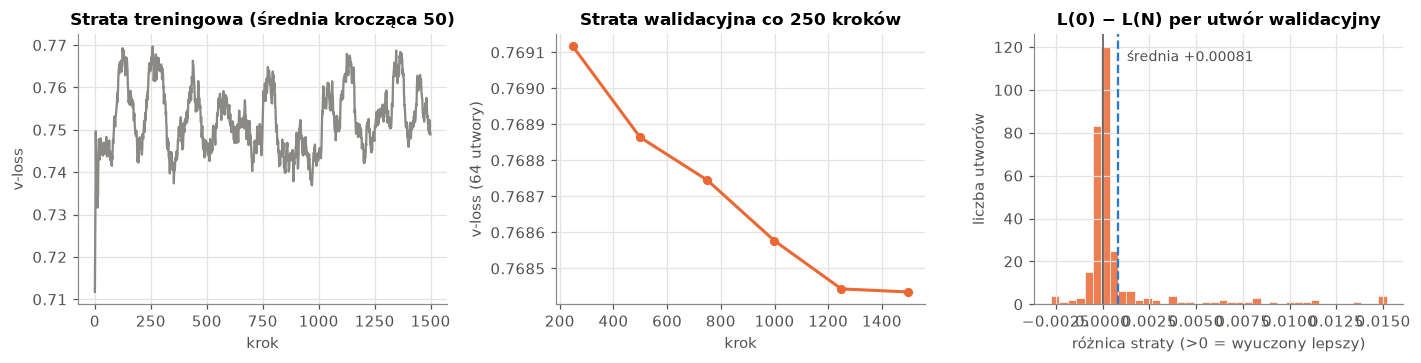

In [3]:
hist = pd.read_csv(RES / "null_music_v1/history_learned_zero.csv")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

ax = axes[0]
ax.plot(hist.step, hist.loss.rolling(50, min_periods=1).mean(), color="#8a8985", lw=1.5)
ax.set(title="Strata treningowa (średnia krocząca 50)", xlabel="krok", ylabel="v-loss")

ax = axes[1]
v = hist.dropna(subset=["val_loss"])
ax.plot(v.step, v.val_loss, color=COLORS["learned"], marker="o", ms=5)
ax.set(title="Strata walidacyjna co 250 kroków", xlabel="krok", ylabel="v-loss (64 utwory)")

ax = axes[2]
lo, hi = diff.quantile([0.01, 0.99])
ax.hist(diff.clip(lo, hi), bins=40, color=COLORS["learned"], alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(0, color="#52514e", lw=1)
ax.axvline(diff.mean(), color=COLORS["zero"], lw=1.5, ls="--")
ax.annotate(f"średnia {diff.mean():+.5f}", (diff.mean(), ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set(title="L(0) − L(N) per utwór walidacyjny", xlabel="różnica straty (>0 = wyuczony lepszy)", ylabel="liczba utworów")
fig.tight_layout()

**Odczyt kroku 1.** Parametryzacja straty jest poprawna (własny opis < null zerowy). P0 jest spełniony: wyuczony null przewiduje odszumianie muzyki lepiej niż zerowy, a przedział ufności wyklucza 0. Efekt jest jednak mały w wartościach bezwzględnych i niesie go część utworów (rozkład różnic jest szeroki, środek blisko zera). Kontrola `T5("")` nie różni się od zera — efekt bierze się z treningu, nie z innej inicjalizacji.

## 4. Krok 2 — przemiatanie CFG

**Siatka (pilot, zbiór seedów A):** 24 prompty muzyczne (Song Describer, bez wokalu; audio z MTG-Jamendo, rozłączne z FMA) + 24 prompty efektów (Clotho v2, ewaluacja) × 3 seedy × $g \in \{1, 2, 3, 4.5, 6, 7, 9, 12\}$ × null ∈ {zero, wyuczony}. 50 kroków samplera SAO (CosineDPMSolver SDE), klipy 10 s. Klip przy $g=1$ nie używa gałęzi null, więc jest generowany raz i wspólny dla obu wariantów: 2160 generacji, 2304 wiersze.

Poniżej tylko diagnostyka sygnału (bez modeli oceniających): poziom szczytowy, odsetek próbek przesterowanych (|x| > 1) i norma $\lVert v_c - v_\varnothing\rVert$ (siła „pchnięcia” CFG) w trakcie próbkowania.

**2304** wierszy, **2160** unikalnych klipów, **48** promptów; commit `db825371`, GPU: Tesla T4, Tesla T4; mediana czasu generacji **15.5 s/klip**.

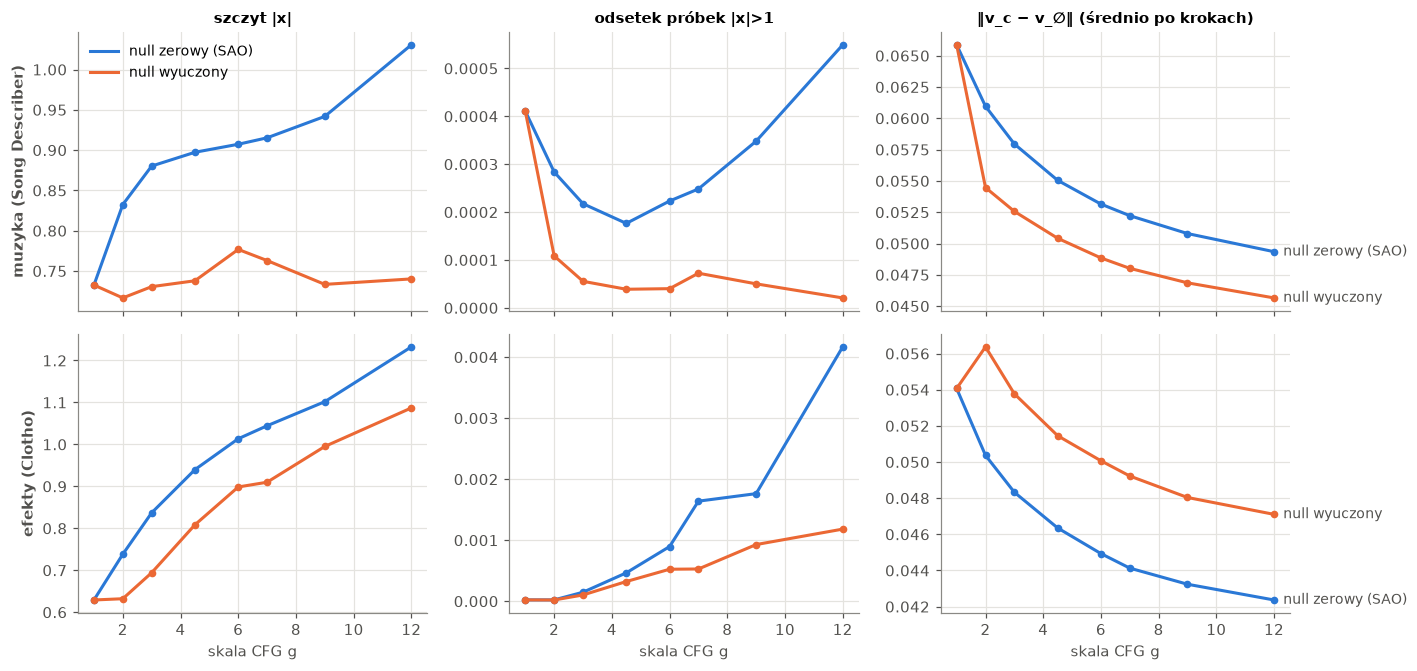

In [4]:
clips = pd.read_parquet(RES / "sweep_pilot_A/clips.parquet")
manifest = json.loads((RES / "sweep_pilot_A/manifest.json").read_text())
display(Markdown(
    f"**{len(clips)}** wierszy, **{clips['clip'].nunique()}** unikalnych klipów, "
    f"**{clips.prompt_id.nunique()}** promptów; commit `{manifest['git']['commit'][:8]}`, "
    f"GPU: {', '.join(manifest['device']['gpus'])}; mediana czasu generacji **{clips.seconds_per_clip.median():.1f} s/klip**."
))

fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for row, domain in enumerate(DOMAINS):
    sub = clips[clips.domain == domain]
    for col, (metric, title) in enumerate([("peak", "szczyt |x|"), ("clipped_frac", "odsetek próbek |x|>1"), ("guidance_rms_mean", "‖v_c − v_∅‖ (średnio po krokach)")]):
        ax = axes[row, col]
        for null in ("zero", "learned"):
            m = sub[sub.null == null].groupby("guidance")[metric].mean()
            ax.plot(m.index, m.values, color=COLORS[null], marker="o", ms=4)
            if col == 2:
                end_label(ax, m.index.values, m.values, null)
        ax.set_title(title if row == 0 else "", fontsize=10)
        if col == 0:
            ax.set_ylabel(DOMAINS[domain], fontsize=10, fontweight="bold")
        if row == 1:
            ax.set_xlabel("skala CFG g")
axes[0, 0].legend([plt.Line2D([], [], color=COLORS[n]) for n in COLORS], LABELS.values(), frameon=False, fontsize=9)
fig.tight_layout()

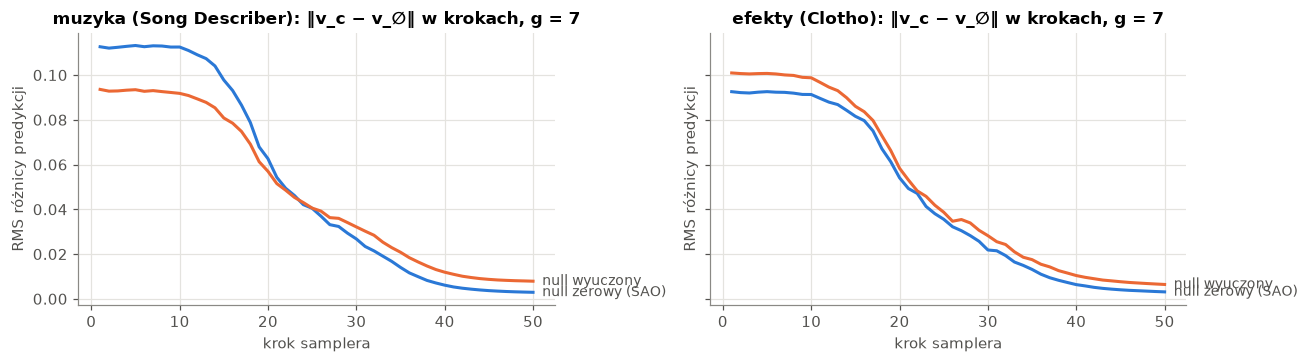

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
for ax, domain in zip(axes, DOMAINS):
    for null in ("zero", "learned"):
        sub = clips[(clips.domain == domain) & (clips.null == null) & (clips.guidance == 7)]
        steps = np.stack(sub.guidance_rms.to_numpy())
        ax.plot(np.arange(1, steps.shape[1] + 1), steps.mean(0), color=COLORS[null])
        end_label(ax, [steps.shape[1]], [steps.mean(0)[-1]], null)
    ax.set(title=f"{DOMAINS[domain]}: ‖v_c − v_∅‖ w krokach, g = 7", xlabel="krok samplera", ylabel="RMS różnicy predykcji")
fig.tight_layout()

**Odczyt kroku 2.** Z nullem zerowym szczyt sygnału i przesterowanie rosną z $g$ (klasyczne przesycenie CFG). Z wyuczonym nullem rosną znacznie wolniej. W muzyce $\lVert v_c - v_\varnothing\rVert$ jest przy wyuczonym nullu mniejsze — to sygnał ostrzegawczy, że wyuczony null może działać jak *mniejsze g*. W efektach dźwiękowych ta norma jest większa, a przesterowania i tak mniej, więc tam to nie jest proste osłabienie guidance. Rozstrzyga dopiero krok 3.

## 5. Krok 3 — ocena

**Metryki** (`configs/score_pilot_A.yaml`, modele przypięte do rewizji HF):
- **zgodność z opisem — CLAP**: kosinus embeddingów audio i tekstu; muzyka: `laion/larger_clap_music_and_speech`, efekty: `laion/larger_clap_general` (drugi model liczony kontrolnie);
- **jakość — Audiobox Aesthetics** (Meta): PQ (production quality, metryka główna), CE (content enjoyment), CU (content usefulness), PC (production complexity);
- **różnorodność — CCDS**: średnia odległość kosinusowa embeddingów CLAP między 3 seedami tego samego promptu przy tym samym $g$ i nullu;
- **odległość od prawdziwej muzyki — FD na embeddingach CLAP** względem 300 nagrań Song Describer (tylko muzyka; dla Clotho nie mamy referencyjnego audio na Kaggle).

Uwaga o metodzie: żadna z tych metryk nie była celem treningu nulla (null uczony był wyłącznie stratą odszumiania), więc wzrost wyniku nie jest „grą pod sędziego”.

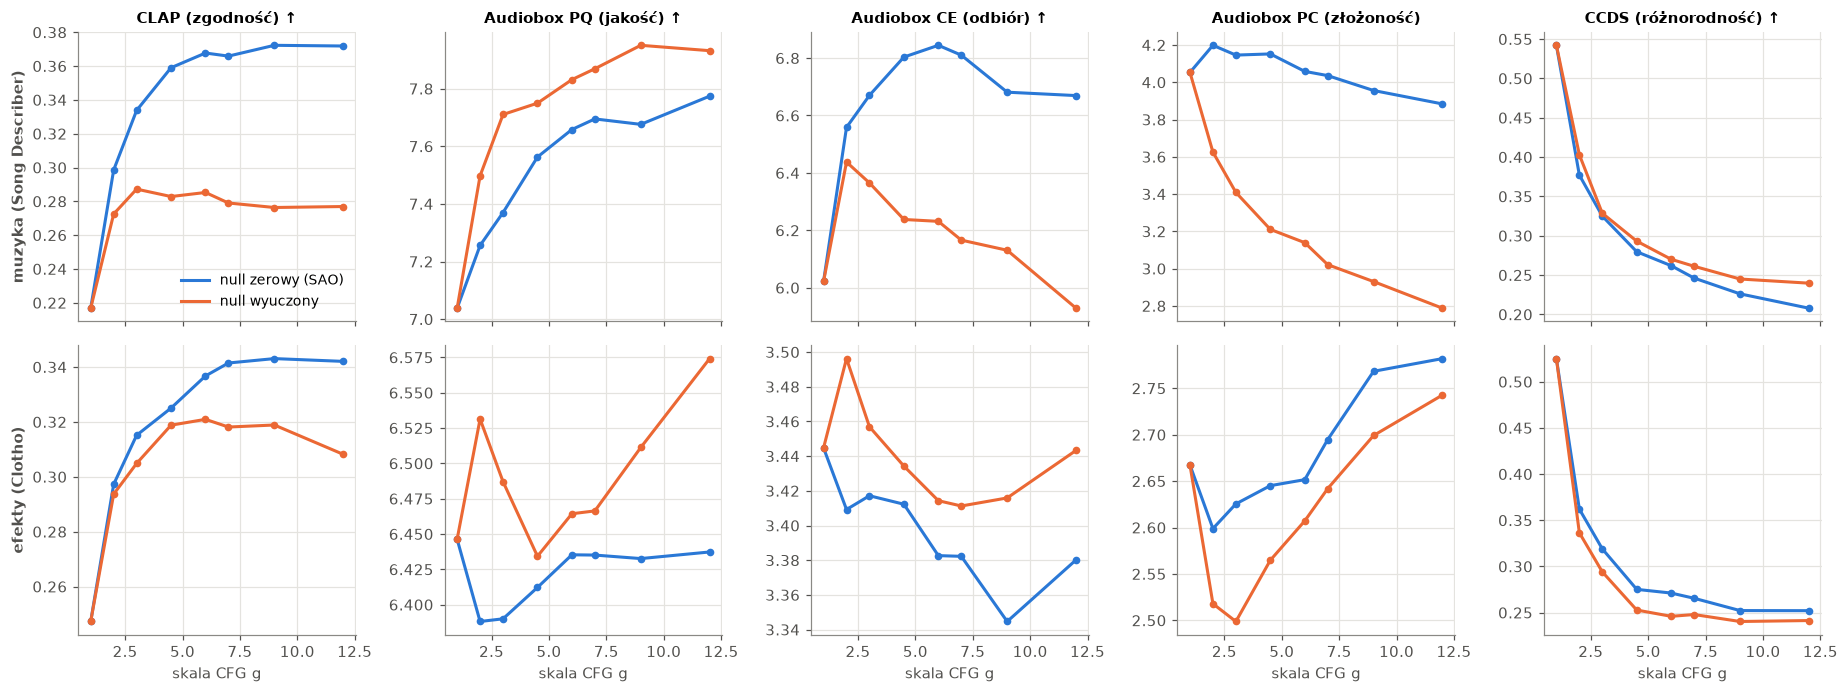

In [6]:
scores = pd.read_parquet(RES / "score_pilot_A/scores.parquet")
diversity = pd.read_parquet(RES / "score_pilot_A/diversity.parquet")
table = per_prompt(scores, diversity)
curve = curves(table)

fig, axes = plt.subplots(2, 5, figsize=(17, 6.4), sharex=True)
for row, domain in enumerate(DOMAINS):
    for col, (metric, title) in enumerate([("clap", "CLAP (zgodność) ↑"), ("PQ", "Audiobox PQ (jakość) ↑"), ("CE", "Audiobox CE (odbiór) ↑"), ("PC", "Audiobox PC (złożoność)"), ("ccds", "CCDS (różnorodność) ↑")]):
        ax = axes[row, col]
        for null in ("zero", "learned"):
            c = curve[(curve.domain == domain) & (curve.null == null)]
            ax.plot(c.guidance, c[metric], color=COLORS[null], marker="o", ms=4)
        ax.set_title(title if row == 0 else "", fontsize=10)
        if col == 0:
            ax.set_ylabel(DOMAINS[domain], fontsize=10, fontweight="bold")
        if row == 1:
            ax.set_xlabel("skala CFG g")
axes[0, 0].legend([plt.Line2D([], [], color=COLORS[n]) for n in COLORS], LABELS.values(), frameon=False, fontsize=9)
fig.tight_layout()

### Front jakość–zgodność

Każdy punkt to jedno $g$ (podpisane). Gdyby wyuczony null był tylko „innym $g$”, jego punkty leżałyby **na** krzywej nulla zerowego. Przewaga oznacza punkty **nad** nią (wyższa jakość przy tej samej zgodności).

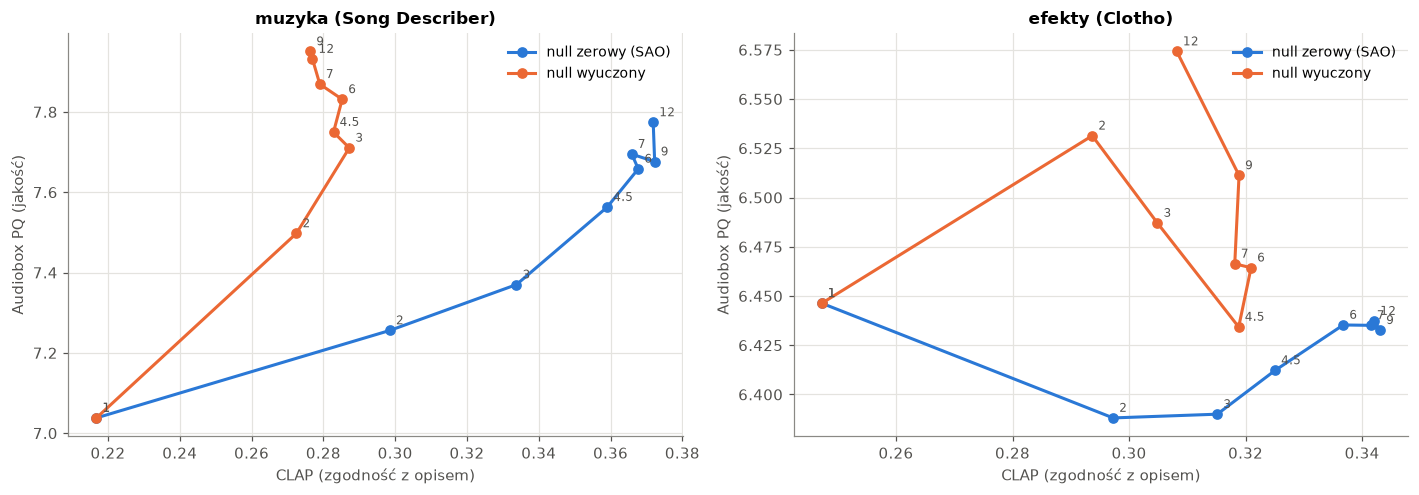

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, domain in zip(axes, DOMAINS):
    for null in ("zero", "learned"):
        c = curve[(curve.domain == domain) & (curve.null == null)].sort_values("guidance")
        ax.plot(c.clap, c.PQ, color=COLORS[null], marker="o", ms=6, label=LABELS[null])
        for _, r in c.iterrows():
            ax.annotate(f"{r.guidance:g}", (r.clap, r.PQ), xytext=(4, 4), textcoords="offset points", fontsize=8, color="#52514e")
    ax.set(title=DOMAINS[domain], xlabel="CLAP (zgodność z opisem)", ylabel="Audiobox PQ (jakość)")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

### Test przy dopasowanym CLAP (kryterium z sekcji 1)

Dla każdego $g'$ wyuczonego nulla: $g^*$ = najmniejsze $g$ (interpolacja liniowa na siatce), przy którym null zerowy osiąga tę samą średnią CLAP; $\Delta = \text{metryka}(\text{wyuczony}, g') - \text{metryka}(\text{zero}, g^*)$. CI: bootstrap po promptach (2000 losowań, pary zachowane). `matched_frac` < 1 znaczy, że w części losowań null zerowy w ogóle nie osiąga takiej zgodności na siatce $g\in[1,12]$.

In [8]:
matched = matched_clap_test(table, metrics=("PQ", "ccds", "CE"), n_boot=2000)

def verdict(r):
    if np.isnan(r.lo):
        return "brak dopasowania"
    if r.lo > 0:
        return "wyuczony lepszy"
    if r.hi < 0:
        return "wyuczony gorszy"
    return "brak różnicy"

matched["wynik"] = matched.apply(verdict, axis=1)
show = matched[matched.metric == "PQ"].drop(columns="metric")
display(Markdown("**Δ PQ przy dopasowanym CLAP**"))
display(show.style.format({"g_star_zero": "{:.2f}", "delta": "{:+.3f}", "lo": "{:+.3f}", "hi": "{:+.3f}", "matched_frac": "{:.0%}"}).hide(axis="index"))
display(Markdown("**Δ CCDS (różnorodność) przy dopasowanym CLAP**"))
display(matched[matched.metric == "ccds"].drop(columns="metric").style.format({"g_star_zero": "{:.2f}", "delta": "{:+.4f}", "lo": "{:+.4f}", "hi": "{:+.4f}", "matched_frac": "{:.0%}"}).hide(axis="index"))

**Δ PQ przy dopasowanym CLAP**

domain,g_learned,g_star_zero,delta,lo,hi,matched_frac,wynik
music,2.000000,1.68,+0.311,+0.207,+0.420,100%,wyuczony lepszy
music,3.000000,1.86,+0.485,+0.335,+0.644,100%,wyuczony lepszy
music,4.500000,1.81,+0.536,+0.345,+0.736,100%,wyuczony lepszy
music,6.000000,1.84,+0.611,+0.418,+0.810,100%,wyuczony lepszy
music,7.000000,1.76,+0.665,+0.482,+0.850,100%,wyuczony lepszy
music,9.000000,1.73,+0.754,+0.546,+0.969,100%,wyuczony lepszy
music,12.000000,1.74,+0.734,+0.504,+0.984,100%,wyuczony lepszy
sfx,2.000000,1.93,+0.139,+0.067,+0.225,100%,wyuczony lepszy
sfx,3.000000,2.43,+0.098,-0.003,+0.220,100%,brak różnicy
sfx,4.500000,3.56,+0.036,-0.118,+0.181,100%,brak różnicy


**Δ CCDS (różnorodność) przy dopasowanym CLAP**

domain,g_learned,g_star_zero,delta,lo,hi,matched_frac,wynik
music,2.000000,1.68,-0.0267,-0.0667,+0.0117,100%,brak różnicy
music,3.000000,1.86,-0.0714,-0.1195,-0.0234,100%,wyuczony gorszy
music,4.500000,1.81,-0.1157,-0.1702,-0.0647,100%,wyuczony gorszy
music,6.000000,1.84,-0.1339,-0.1862,-0.0802,100%,wyuczony gorszy
music,7.000000,1.76,-0.1553,-0.2048,-0.1049,100%,wyuczony gorszy
music,9.000000,1.73,-0.1769,-0.2264,-0.1246,100%,wyuczony gorszy
music,12.000000,1.74,-0.1810,-0.2354,-0.1291,100%,wyuczony gorszy
sfx,2.000000,1.93,-0.0373,-0.0833,+0.0065,100%,brak różnicy
sfx,3.000000,2.43,-0.0496,-0.1035,+0.0128,100%,brak różnicy
sfx,4.500000,3.56,-0.0500,-0.1065,-0.0114,100%,wyuczony gorszy


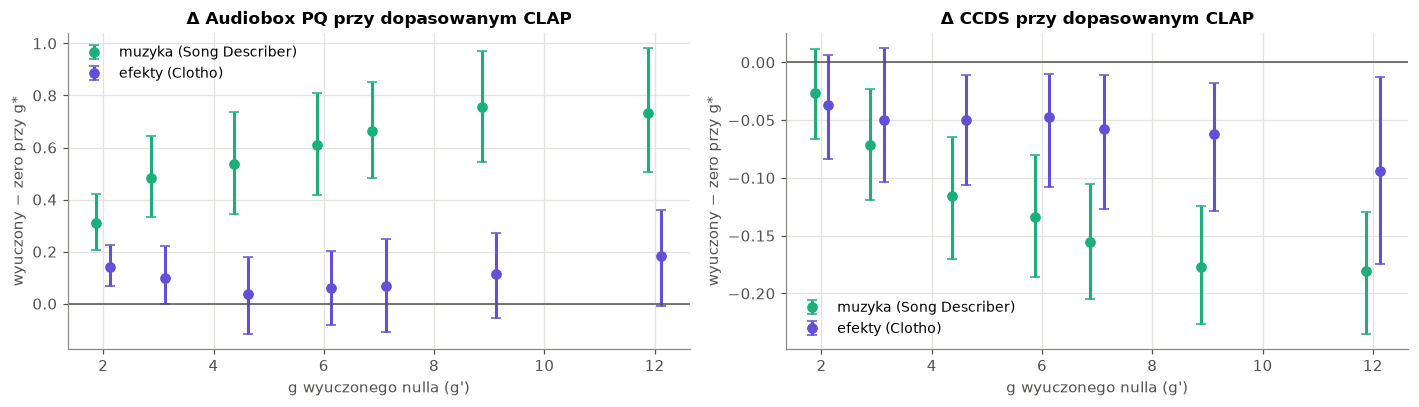

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=False)
for ax, metric, title in [(axes[0], "PQ", "Δ Audiobox PQ przy dopasowanym CLAP"), (axes[1], "ccds", "Δ CCDS przy dopasowanym CLAP")]:
    for i, domain in enumerate(DOMAINS):
        m = matched[(matched.metric == metric) & (matched.domain == domain)]
        x = m.g_learned + (i - 0.5) * 0.25
        ax.errorbar(x, m.delta, yerr=[m.delta - m.lo, m.hi - m.delta], fmt="o", ms=6, capsize=3,
                    color=["#1baf7a", "#6250d6"][i], label=DOMAINS[domain])
    ax.axhline(0, color="#52514e", lw=1)
    ax.set(title=title, xlabel="g wyuczonego nulla (g')", ylabel="wyuczony − zero przy g*")
    ax.legend(frameon=False, fontsize=9)
fig.tight_layout()

### Dodatkowo: różnice przy tym samym $g$ i FD dla muzyki

Porównanie przy *tym samym* $g$ nie rozstrzyga hipotezy (miesza efekt nulla z siłą guidance), ale pokazuje, co dokładnie zmienia wyuczony null.

In [10]:
same = same_g_differences(table)
pivot = same.pivot_table(index=["domain", "guidance"], columns="metric", values="mean")[["clap", "PQ", "CE", "CU", "PC", "ccds"]]
display(Markdown("**Średnia różnica wyuczony − zero przy tym samym g** (pogrubione: 95% CI wyklucza 0)"))
sig = same.assign(sig=(same.lo > 0) | (same.hi < 0)).pivot_table(index=["domain", "guidance"], columns="metric", values="sig")[pivot.columns]
display(pivot.style.format("{:+.3f}").apply(lambda _: np.where(sig.astype(bool), "font-weight: bold", ""), axis=None))

fd_path = RES / "score_pilot_A/fd_music.csv"  # pojawi się po ponownym przeliczeniu referencji
if fd_path.exists():
    fd = pd.read_csv(fd_path)
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    for null in ("zero", "learned"):
        f = fd[fd.null == null].sort_values("guidance")
        ax.plot(f.guidance, f.fd_music, color=COLORS[null], marker="o", ms=4)
        end_label(ax, f.guidance.values, f.fd_music.values, null)
    ax.set(title="Muzyka: FD (CLAP) do nagrań Song Describer ↓", xlabel="skala CFG g", ylabel="FD")
    fig.tight_layout()

**Średnia różnica wyuczony − zero przy tym samym g** (pogrubione: 95% CI wyklucza 0)

## 6. Wnioski, ograniczenia, dalsze kroki

**Krótko: w pilocie hipoteza w zapisanej postaci się nie potwierdza. Wyuczony null daje inny kompromis niż CFG, ale go nie dominuje.**

1. **Krok 1 (P0) — spełniony.** Wyuczony null obniża stratę odszumiania na niewidzianych artystach (+0,00081, 95% CI [0,00047; 0,00117]), czyli około 60% zysku, jaki daje prawdziwy opis. Efekt jest mały i niesie go część utworów.
2. **Zgodność z opisem spada i nie da się jej odzyskać skalą g.** Z wyuczonym nullem CLAP w muzyce wypłaszcza się na ≈0,28 (null zerowy dochodzi do ≈0,37). Dopasowanie po CLAP wypada więc zawsze przy $g^* \approx 1{,}7$–$1{,}9$ nulla zerowego, niezależnie od $g'$. W efektach spadek jest mniejszy (≈0,32 wobec ≈0,34).
3. **Przy dopasowanym CLAP jakość PQ jest wyższa** (muzyka: +0,3 do +0,75 PQ, CI wyklucza 0 dla każdego $g'$; efekty: +0,04 do +0,19, istotne tylko przy $g'=2$). Tego zwykły CFG nie daje: w tym sensie efekt *nie* jest „po prostu innym g”.
4. **Ale różnorodność spada** (CCDS przy dopasowanym CLAP: muzyka −0,07 do −0,18, efekty −0,05 do −0,09, większość CI wyklucza 0), a w muzyce spadają też **CE** (odbiór treści, istotnie przy $g' \ge 9$) i wyraźnie **PC** (złożoność produkcji: ≈3,0 wobec ≈4,0 przy $g=7$). Wyższe PQ idzie więc w parze z prostszym, mniej zróżnicowanym i mniej zgodnym z opisem materiałem; część zysku PQ może wynikać z tego, że Audiobox PQ nagradza prostszy sygnał.
5. **Diagnostyka sygnału** (krok 2) jest spójna z tym obrazem: z wyuczonym nullem znacznie mniej przesterowania przy dużym $g$.

**Werdykt według kryterium z sekcji 1:** warunek „wyższa jakość przy porównywalnej zgodności” jest spełniony tylko przy zgodności typowej dla $g\approx1{,}8$, a warunek „różnorodność nie spada” — nie. Przewagi w sensie hipotezy nie wykazaliśmy. Najciekawszy pozytywny wynik to **odporność na przesterowanie**: z nullem zerowym odsetek próbek |x|>1 rośnie z $g$ kilkukrotnie, z wyuczonym prawie nie rośnie (muzyka) lub rośnie wolniej (efekty). Samo PQ nie spada przy dużym $g$ w żadnym wariancie.

**Hipoteza robocza na dalsze kroki.** Null uczony bezwarunkową stratą odszumiania zbliża się do „typowej muzyki z FMA”, więc gałąź warunkowa i bezwarunkowa stają się do siebie podobniejsze, a CFG słabiej pcha w stronę opisu (mniejsze $\lVert v_c - v_\varnothing\rVert$ w muzyce). Sprawdzić: (a) null o mniejszej normie (wczesne zatrzymanie / regularyzacja w stronę 0), (b) interpolację $\alpha N$, $\alpha\in[0,1]$, jako drugi pokrętło obok $g$ — czy istnieje $\alpha$, które poprawia PQ bez utraty CLAP i CCDS.

**Uwaga do FD:** pierwsze przeliczenie zebrało tylko 10 z 300 nagrań referencyjnych (mp3 dekodowało się kilka próbek krócej niż wymagany fragment). Błąd jest poprawiony; FD zostanie dołączone po ponownym uruchomieniu joba `score`.

**Ograniczenia pilota.**
- 24 prompty na domenę × 3 seedy: CI są szerokie; efekty rzędu kilku setnych PQ są poniżej rozdzielczości.
- CLAP i Audiobox to automatyczni sędziowie; Audiobox był trenowany na ocenach ludzi, ale nie na audio z SAO.
- FD liczone na 72 klipach na warunek jest obciążone (porównujemy tylko warianty między sobą, przy tym samym n); brak FD dla efektów.
- Null trenowany tylko na muzyce (FMA); prompty efektów sprawdzają przenoszenie poza domenę treningu.

**Dalsze kroki (w kolejności).**
1. Ponowne uruchomienie `score` (poprawione FD) i ślepy odsłuch A/B par (wyuczony przy $g'$ kontra zero przy najbliższym $g^*$), zespół + CI z odsetka preferencji.
2. Replikacja na zbiorze seedów B (`seed_set: B`) oraz przemiatanie $lpha N$ — wynik musi się powtórzyć.
3. Dopiero po powtarzalnym zysku (zgodnie z planem prowadzącego): drugi generator i wariant ReNeg (null uczony nagrodą) z niezależnym sędzią końcowym.